# Assignment 07 - Clustering

This assignment will guide you through clustering algorithms: K-Means and DBSCAN. You'll learn how to preprocess data, find the optimal number of clusters, and understand when different algorithms work best.

### Import essential libraries
You can also import them while working on the assignment when needed.

In [10]:
# وما توفيقي الا بالله
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

---

## Part 1: The Clean-Up (Preprocessing)

**Context:** K-Means calculates the distance between points. If one column is "Age" (0-100) and another is "Income" (0-100,000), the Income column will dominate the distance calculation.

**Task:**
1. Load the `Mall_Customers.csv` file
2. Select the features: `Annual Income (k$)` and `Spending Score (1-100)`
3. **Crucial Step:** Apply `StandardScaler` to normalize these features
4. Plot the datapoints (Using scatter plot for example)

Shape: (200, 5)
Missing values: 0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00
mean,60.56,50.20
std,26.26,25.82
min,15.00,1.00
25%,41.50,34.75
50%,61.50,50.00
75%,78.00,73.00
max,137.00,99.00


Scaled mean: [-0. -0.]
Scaled std : [1. 1.]


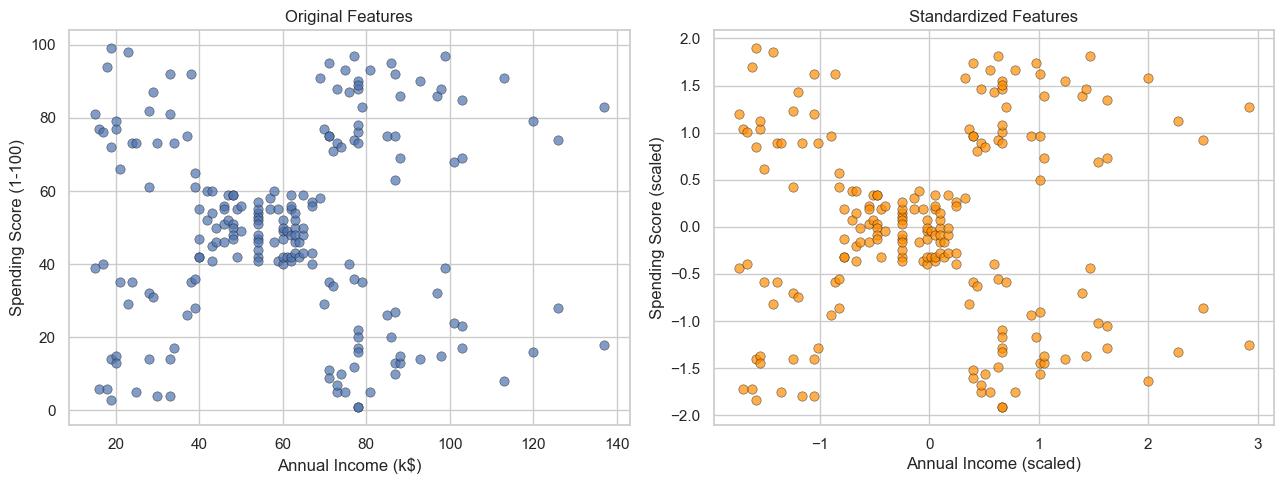

In [11]:
# 1. Load the data
df = pd.read_csv("Mall_Customers.csv")
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
display(df.head())

# 2. Select the features
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()
display(X.describe().round(2))

# 3. Standardize the features (mean = 0, std = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled mean:", X_scaled.mean(axis=0).round(6))
print("Scaled std :", X_scaled.std(axis=0).round(6))

# 4. Plot the data points (original vs. scaled)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X[features[0]], X[features[1]], s=45, alpha=0.7, edgecolor="k", linewidth=0.4)
axes[0].set_title("Original Features")
axes[0].set_xlabel(features[0]); axes[0].set_ylabel(features[1])

axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], s=45, alpha=0.7, color="darkorange", edgecolor="k", linewidth=0.4)
axes[1].set_title("Standardized Features")
axes[1].set_xlabel("Annual Income (scaled)"); axes[1].set_ylabel("Spending Score (scaled)")
plt.tight_layout()
plt.show()

**Observation:** Even before running any algorithm, the scatter plot shows visibly distinct groups of customers (notably a dense block in the center and several groups in the corners). Standardization keeps the shape of the data unchanged but puts both features on the same scale, so neither dominates the distance calculation in K-Means.

---

## Part 2: The Hunt for K (K-Means)

**Context:** You don't know how many customer groups exist. Is it 3? 5? 10?

**Task:**
1. Run K-Means for $K=2$ to $K=10$
2. Calculate the WCSS (Within-Cluster Sum of Squares) for each
3. Plot the "Elbow Curve", Where does the elbow bend?
5. **Validate:** Calculate the Silhouette Score for your chosen $K$ to confirm it's a good split

,K,WCSS,Silhouette
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.8648,0.5281
6,8,37.2282,0.4552
7,9,32.3923,0.4571
8,10,29.9819,0.4432


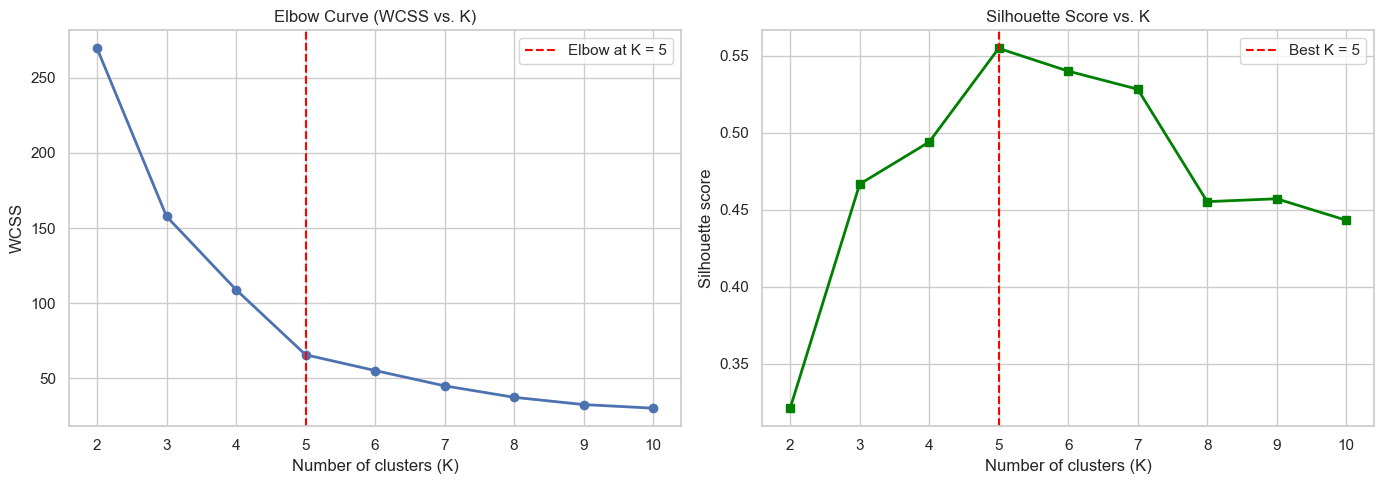

Silhouette Score for K = 5: 0.5547
Highest silhouette among all K tested: K = 5


In [12]:
k_values = range(2, 11)
wcss, sil_scores = [], []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)                      # WCSS
    sil_scores.append(silhouette_score(X_scaled, labels))

results = pd.DataFrame({"K": list(k_values), "WCSS": wcss, "Silhouette": sil_scores}).round(4)
display(results)

# Elbow curve + Silhouette curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, wcss, marker="o", linewidth=2)
axes[0].axvline(5, color="red", linestyle="--", label="Elbow at K = 5")
axes[0].set_title("Elbow Curve (WCSS vs. K)")
axes[0].set_xlabel("Number of clusters (K)"); axes[0].set_ylabel("WCSS")
axes[0].legend()

axes[1].plot(k_values, sil_scores, marker="s", color="green", linewidth=2)
axes[1].axvline(5, color="red", linestyle="--", label="Best K = 5")
axes[1].set_title("Silhouette Score vs. K")
axes[1].set_xlabel("Number of clusters (K)"); axes[1].set_ylabel("Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.show()

# Validate the chosen K
best_k = 5
final_labels = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
print(f"Silhouette Score for K = {best_k}: {silhouette_score(X_scaled, final_labels):.4f}")
print(f"Highest silhouette among all K tested: K = {results.loc[results['Silhouette'].idxmax(), 'K']:.0f}")

**Where does the elbow bend?** The WCSS drops sharply from K=2 to K=5 (about 270 to 66) and then flattens (66 to 55 at K=6, and only small gains afterwards). The elbow is therefore at **K = 5**.

**Validation:** The Silhouette Score peaks at K = 5 (about 0.55), which is higher than every other K tested. A score above 0.5 indicates a reasonably strong, well-separated clustering structure, which confirms K = 5 as a good choice.

---

## Part 3: The Reveal (Visualization & Interpretation)

**Context:** The marketing team doesn't understand math. They need a chart.

**Task:**
1. Train the final K-Means model with your chosen $K$
2. Create a Scatter Plot:
   - X-axis: Annual Income
   - Y-axis: Spending Score
   - Color the points based on their Cluster Label
   - Mark the Centroids (the center of each group) with a big 'X'

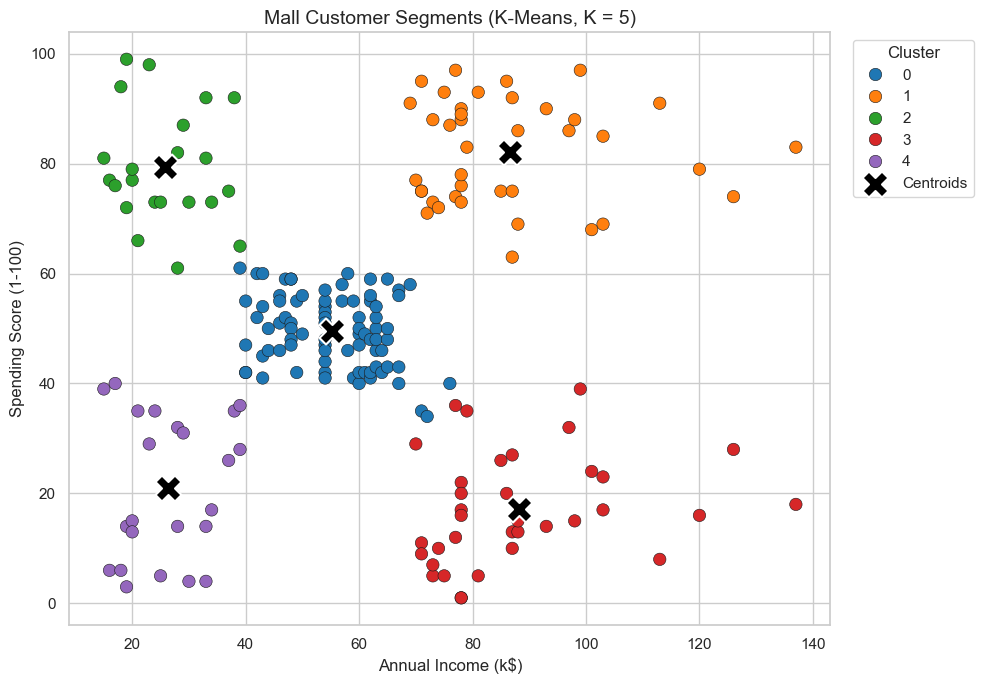

,Customers,Avg_Income,Avg_Spending
Cluster,,,
0,81,55.3,49.5
1,39,86.5,82.1
2,22,25.7,79.4
3,35,88.2,17.1
4,23,26.3,20.9


In [13]:
# Train the final model
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Convert centroids back to the original scale so they match the axes
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
    hue="Cluster", palette="tab10", s=80, edgecolor="k", linewidth=0.4
)
plt.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=350, c="black",
            edgecolor="white", linewidth=1.5, label="Centroids", zorder=5)
plt.title("Mall Customer Segments (K-Means, K = 5)", fontsize=14)
plt.xlabel("Annual Income (k$)"); plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Cluster profile (for the marketing team)
profile = (df.groupby("Cluster")
             .agg(Customers=("CustomerID", "count"),
                  Avg_Income=("Annual Income (k$)", "mean"),
                  Avg_Spending=("Spending Score (1-100)", "mean"))
             .round(1))
display(profile)

**Interpretation for the marketing team** (cluster numbers match the profile table above):

| Cluster | Customers | Income | Spending | Segment | Suggested action |
|---|---|---|---|---|---|
| 1 | 39 | High (~87k) | High (~82) | Target customers | VIP / loyalty programs |
| 3 | 35 | High (~88k) | Low (~17) | Careful spenders | Personalized offers to raise engagement |
| 0 | 81 | Medium (~55k) | Medium (~50) | Standard customers | Regular promotions |
| 4 | 23 | Low (~26k) | Low (~21) | Budget-conscious customers | Discounts and budget deals |
| 2 | 22 | Low (~26k) | High (~79) | Impulsive spenders | Trendy products, installment offers |

---

## Part 4: The "Glitch" (DBSCAN vs. K-Means)

**Context:** Your boss suspects the data might get messy in the future. She asks, "What if the customer groups aren't round blobs? What if they are shaped like crescents or rings?"

### Step 1: Generate Synthetic Data

**Task:** Generate synthetic moon-shaped data using the following code:

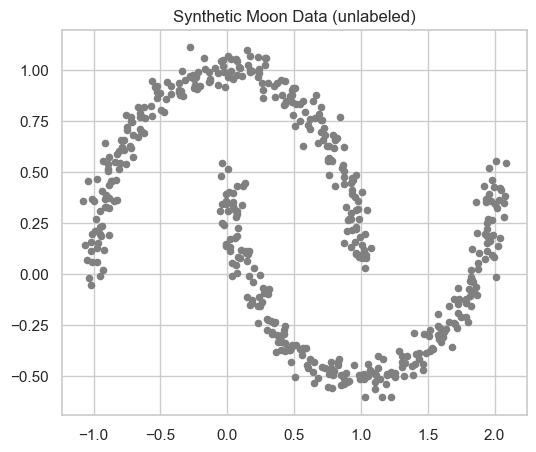

In [14]:
from sklearn.datasets import make_moons
X_moon, y_moon = make_moons(n_samples=500, noise=0.05, random_state=42)

plt.figure(figsize=(6, 5))
plt.scatter(X_moon[:, 0], X_moon[:, 1], s=20, color="gray")
plt.title("Synthetic Moon Data (unlabeled)")
plt.show()

### Step 2: Fail Test - K-Means on Moon Data

**Task:** Run K-Means on the Moon data and plot it. Does it look right? (Spoiler: No, it cuts the moons in half)  
**Note:** We only need 2 centroids (Two Clusters)

- **Fit K-Means (K=2):** Train K-Means on `X_moon` with 2 clusters.  
- **Predict labels:** Use the fitted model to get cluster labels.  
- **Plot results:** Scatter plot `X_moon` and color by cluster labels. (*Optional:* Plot Cluster centroids positions)

*Outcomes Does it correctly split the two moons ?*

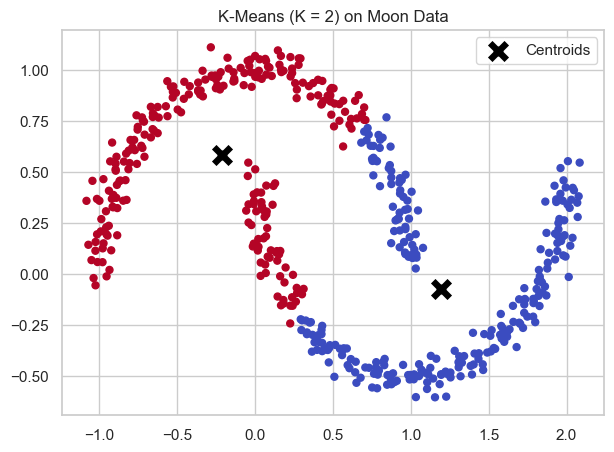

Adjusted Rand Index vs. true moons: 0.253


In [15]:
# Fit K-Means with K = 2
km_moon = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
km_labels = km_moon.fit_predict(X_moon)

plt.figure(figsize=(7, 5))
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=km_labels, cmap="coolwarm", s=25)
plt.scatter(km_moon.cluster_centers_[:, 0], km_moon.cluster_centers_[:, 1],
            marker="X", s=300, c="black", edgecolor="white", linewidth=1.5, label="Centroids")
plt.title("K-Means (K = 2) on Moon Data")
plt.legend()
plt.show()

print(f"Adjusted Rand Index vs. true moons: {adjusted_rand_score(y_moon, km_labels):.3f}")

**Outcome:** No, K-Means does **not** split the two moons correctly. It cuts the data with a straight line between the two centroids, so each cluster contains parts of both moons. The Adjusted Rand Index is far from 1, which confirms the poor match.

### Step 3: Success Test - DBSCAN on Moon Data

**Task:** Run DBSCAN on the Moon data. Tune `eps` and `min_samples` until you perfectly capture the two crescent shapes.

- **Fit DBSCAN:** Train DBSCAN on `X_moon` with different `eps` and `min_samples` values using `fit_predict()`.
- **Plot results:** Create scatter plots of `X_moon` colored by cluster labels for different parameter combinations.
- **Objective:** Find the parameter values that best separate the two moon shapes without incorrectly merging or splitting them.

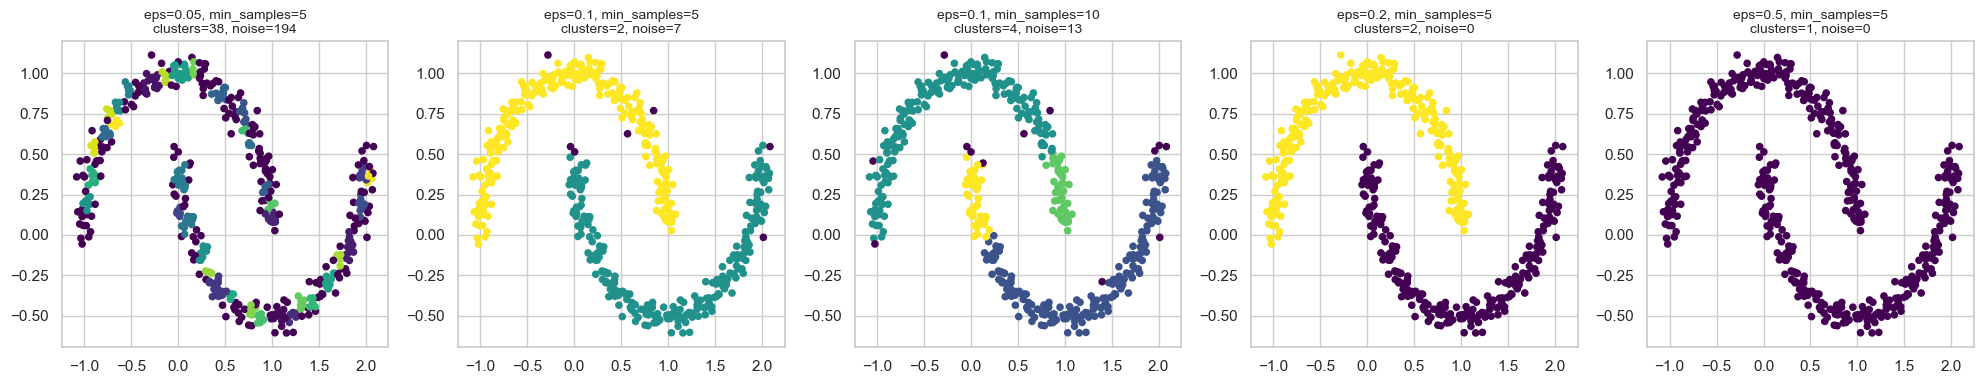

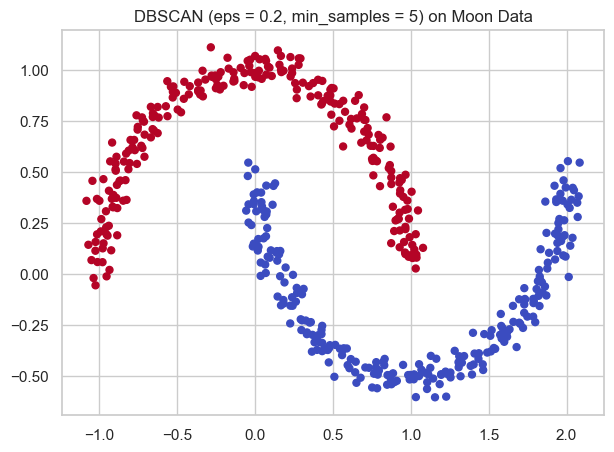

Clusters found: 2
Noise points  : 0
Adjusted Rand Index vs. true moons: 1.000


In [16]:
# Try several parameter combinations
param_grid = [(0.05, 5), (0.1, 5), (0.1, 10), (0.2, 5), (0.5, 5)]

fig, axes = plt.subplots(1, len(param_grid), figsize=(20, 4))
for ax, (eps, ms) in zip(axes, param_grid):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_moon)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    ax.scatter(X_moon[:, 0], X_moon[:, 1], c=labels, cmap="viridis", s=20)
    ax.set_title(f"eps={eps}, min_samples={ms}\nclusters={n_clusters}, noise={n_noise}", fontsize=10)
plt.tight_layout()
plt.show()

# Best parameters
best_eps, best_ms = 0.2, 5
db = DBSCAN(eps=best_eps, min_samples=best_ms)
db_labels = db.fit_predict(X_moon)

plt.figure(figsize=(7, 5))
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=db_labels, cmap="coolwarm", s=25)
plt.title(f"DBSCAN (eps = {best_eps}, min_samples = {best_ms}) on Moon Data")
plt.show()

print("Clusters found:", len(set(db_labels)) - (1 if -1 in db_labels else 0))
print("Noise points  :", int((db_labels == -1).sum()))
print(f"Adjusted Rand Index vs. true moons: {adjusted_rand_score(y_moon, db_labels):.3f}")

**Parameter analysis:**
- `eps = 0.05`: too small, so the moons fragment into many small clusters and lots of noise points.
- `eps = 0.1`: close, but a few points are still flagged as noise (and with `min_samples = 10` a moon gets split).
- `eps = 0.2`, `min_samples = 5`: **best**, with exactly two clusters, zero noise and an Adjusted Rand Index of 1.0 (a perfect match).
- `eps = 0.5`: too large, so both moons merge into a single cluster.

### Step 4: Reflection (Optional)

**Question:** Why did DBSCAN win here? Write your answer below.

**Your Answer:**

DBSCAN won because it is **density-based**, while K-Means is **centroid-based**.

1. **K-Means assumes convex, roughly spherical clusters.** It assigns every point to the nearest centroid, so the boundary between two clusters is always a straight line. Two interlocking crescents cannot be separated by a straight line, so K-Means cuts straight through both moons.
2. **DBSCAN groups points by density and connectivity.** It starts from a core point and keeps expanding through neighbouring points that lie within `eps`. A chain of dense points can follow a curved shape, so each crescent is recognized as one continuous cluster, however irregular its shape.
3. **No need to specify the number of clusters.** DBSCAN discovers the number of clusters from the data, and it labels outliers as noise (`-1`) instead of forcing them into a cluster.

**Trade-off:** DBSCAN is sensitive to `eps` and `min_samples` (as seen above) and struggles when clusters have very different densities. K-Means remains the better choice for compact, well-separated, blob-like groups such as the mall customer segments.